# Examen Parcial - ALgoritmos Geneticos

Utilizar la biblioteca `pyGAD` para optimizar una Red Neuronal Convolucional Profunda (CNN) mediante un Algoritmo Genético,

### integrantes
- Isabel Quintanar Jose
- Isaí Paz Ortiz
- Jesús Antonio Rosario Hernández

## Importaciones

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pygad
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
        
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD, Adam, RMSprop
from tensorflow.keras.utils import to_categorical

I0000 00:00:1790705267.839468    7618 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Constantes

In [2]:
SEED = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.25

CLASSNAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
LEN_CLASSNAMES = NUM_CLASSES = len(CLASSNAMES)

MAX_PIXEL_VALUE = 255

INPUT_SHAPE = (32, 32, 3)
FILTER1_SIZE = 32
FILTER2_SIZE = 64
FILTER_SHAPE = (3, 3)
POOL_SHAPE = (2, 2)
FULLY_CONNECT_NUM = 128

BATCH_SIZE = 32
EPOCHS = 30
METRICS = metrics=['accuracy', Precision(name='precision'), Recall(name='recall')]

MAX_CONV_LAYERS = 3
FILTERS_MIN, FILTERS_MAX = 16, 128
KERNEL_OPTIONS = [3, 5]
DENSE_MIN, DENSE_MAX = 64, 256
OPTIMIZERS = ['adam', 'rmsprop', 'sgd']
OPTIMIZER_CLASSES = {'adam': Adam, 'rmsprop': RMSprop, 'sgd': SGD}

NUM_GENES = 4 + MAX_CONV_LAYERS + 3

FITNESS_EPOCHS = 5
NUM_GENERATIONS = 30
NUM_PARENTS = 2
SOLS_PER_POP = 15

I0000 00:00:1790705273.185956    7618 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2115 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


## Carga del dataset

In [3]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = cifar10.load_data()

### Separación de los datos: (60, 20, 20)

In [4]:
x = np.concatenate([x_train_full, x_test_full])
y = np.concatenate([y_train_full, y_test_full])



x_train_val, x_test, y_train_val, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
x_train, x_val, y_train, y_val = train_test_split(x_train_val, y_train_val, test_size=VALIDATION_SIZE, random_state=SEED, stratify=y_train_val)

y_train_cat = to_categorical(y_train, num_classes=LEN_CLASSNAMES)
y_val_cat = to_categorical(y_val, num_classes=LEN_CLASSNAMES)
y_test_cat = to_categorical(y_test, num_classes=LEN_CLASSNAMES)

print(f'Train: {x_train.shape[0]} ({x_train.shape[0]/len(x)*100:.1f}%)')
print(f'Validation: {x_val.shape[0]} ({x_val.shape[0]/len(x)*100:.1f}%)')
print(f'Test: {x_test.shape[0]} ({x_test.shape[0]/len(x)*100:.1f}%)')

Train: 36000 (60.0%)
Validation: 12000 (20.0%)
Test: 12000 (20.0%)


### Normalización de los datos

In [5]:
x_train_norm = x_train.astype('float32') / MAX_PIXEL_VALUE
x_val_norm = x_val.astype('float32') / MAX_PIXEL_VALUE
x_test_norm = x_test.astype('float32') / MAX_PIXEL_VALUE

### Imágenes de muestra

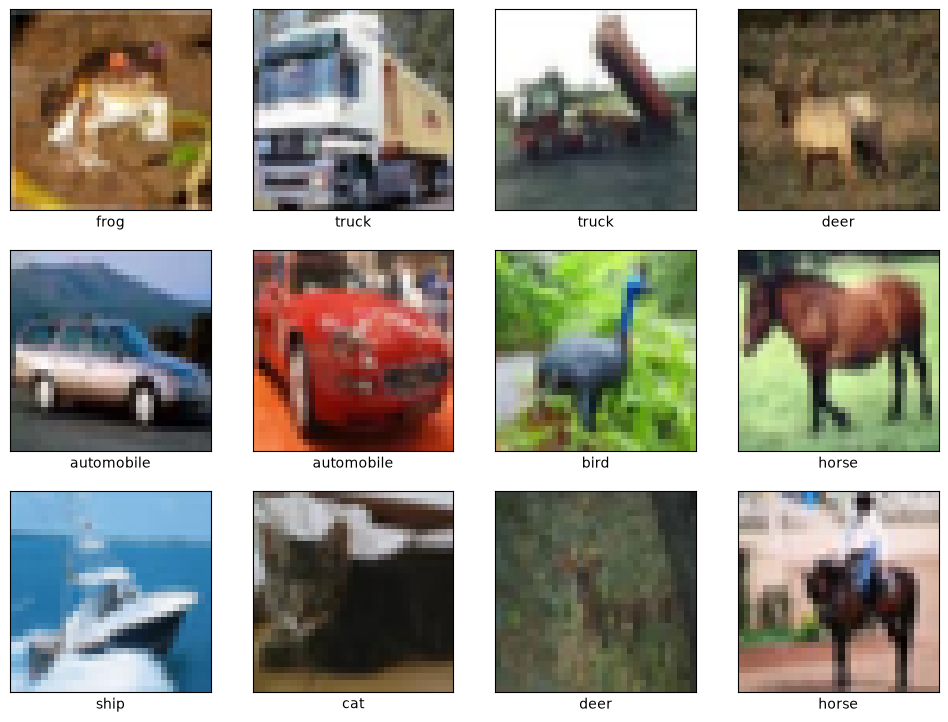

In [6]:
plt.figure(figsize=(12, 12))
for i in range(12):
    plt.subplot(4, 4, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train_full[i], cmap=plt.cm.binary)
    plt.xlabel(CLASSNAMES[y_train_full[i][0]])
plt.show()

## Fase 1: Evaluación de la Red Base

In [8]:
def build_baseline():
    model = Sequential()
    model.add(Conv2D(FILTER1_SIZE, FILTER_SHAPE, activation='relu', input_shape=INPUT_SHAPE))
    model.add(MaxPooling2D(POOL_SHAPE))
    model.add(Conv2D(FILTER2_SIZE, FILTER_SHAPE, activation='relu'))
    model.add(MaxPooling2D(POOL_SHAPE))
    model.add(Flatten())
    model.add(Dense(FULLY_CONNECT_NUM, activation='relu'))
    model.add(Dense(NUM_CLASSES, activation='softmax'))
    return model

In [9]:
baseline_model = build_baseline()
baseline_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=METRICS
)
baseline_model.summary()

/home/Jesus/miniconda3/envs/ml-course/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
start_time = time.time()
history_baseline = baseline_model.fit(x_train_norm, y_train_cat, validation_data=(x_val_norm, y_val_cat), epochs=EPOCHS, batch_size=BATCH_SIZE)
baseline_train_time = time.time() - start_time

print(f'Tiempo de entrenamiento: {baseline_train_time:.2f}s')

Epoch 1/30


I0000 00:00:1790705277.803745    7695 service.cc:153] XLA service 0x7ff1b8035290 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790705277.803766    7695 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.9.0; DNN: 9.23.1)
I0000 00:00:1790705277.842448    7695 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790705277.985170    7695 cuda_dnn.cc:461] Loaded cuDNN version 92301
I0000 00:00:1790705277.994194    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1837__.38


  64/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.1938 - loss: 2.1838 - precision: 0.0000e+00 - recall: 0.0000e+00

I0000 00:00:1790705282.124475    7695 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.4523 - loss: 1.5264 - precision: 0.6927 - recall: 0.2085 - val_accuracy: 0.5458 - val_loss: 1.2999 - val_precision: 0.7222 - val_recall: 0.3542
Epoch 2/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5859 - loss: 1.1759 - precision: 0.7445 - recall: 0.4141 - val_accuracy: 0.6165 - val_loss: 1.0995 - val_precision: 0.7601 - val_recall: 0.4548
Epoch 3/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6414 - loss: 1.0287 - precision: 0.7722 - recall: 0.5035 - val_accuracy: 0.6447 - val_loss: 1.0272 - val_precision: 0.7762 - val_recall: 0.5002
Epoch 4/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6792 - loss: 0.9202 - precision: 0.7899 - recall: 0.5643 - val_accuracy: 0.6576 - val_loss: 0.9859 - val_precision: 0.7562 - val_recall: 0.5537
Epoch 5/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7087 - loss: 0.8348 - precision: 0.8056 - recall: 0.6111 - val_accuracy: 0.6604 - val_loss: 0.9

In [11]:
resultados = baseline_model.evaluate(x_test_norm, y_test_cat, return_dict=True)
print(resultados)

test_loss = resultados['loss']
test_accuracy = resultados['accuracy']
baseline_params = baseline_model.count_params()

375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6461 - loss: 2.8703 - precision: 0.6536 - recall: 0.6413
{'accuracy': 0.6460833549499512, 'loss': 2.8703277111053467, 'precision': 0.6535586714744568, 'recall': 0.6412500143051147}


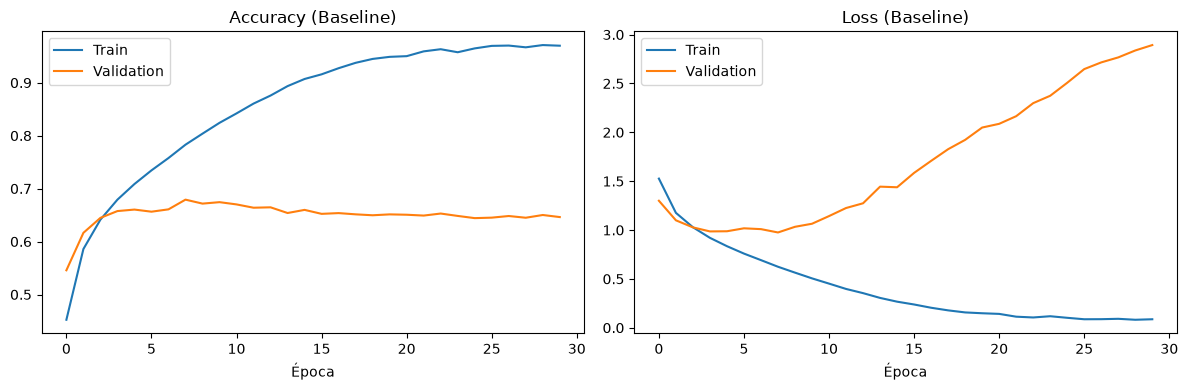

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_baseline.history['accuracy'], label='Train')
axes[0].plot(history_baseline.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy (Baseline)')
axes[0].set_xlabel('Época')
axes[0].legend()

axes[1].plot(history_baseline.history['loss'], label='Train')
axes[1].plot(history_baseline.history['val_loss'], label='Validation')
axes[1].set_title('Loss (Baseline)')
axes[1].set_xlabel('Época')
axes[1].legend()

plt.tight_layout()
plt.show()

## Fase 2: Optimización mediante `PyGAD`

In [13]:
W1 = 0.7
W2 = 0.3
TP_MIN = 1000
TP_MAX = baseline_params
eval_log = []
cache = {}
gen_best, gen_mean = [], []

gene_space = (
    [{'low': 0.0001, 'high': 0.01}] +                          # learning_rate
    [{'low': 16, 'high': 128}] +                                # batch_size
    [{'low': 0, 'high': len(OPTIMIZERS) - 1}] +                 # optimizer (índice)
    [{'low': 1, 'high': MAX_CONV_LAYERS}] +                     # n_conv_layers
    [{'low': FILTERS_MIN, 'high': FILTERS_MAX}] * MAX_CONV_LAYERS +  # filtros por capa
    [{'low': 0, 'high': len(KERNEL_OPTIONS) - 1}] +             # kernel_size (índice)
    [{'low': DENSE_MIN, 'high': DENSE_MAX}] +                   # dense_units
    [{'low': 0.0, 'high': 0.5}]                                 # dropout
)

In [14]:
# [0.001,               64,         0,          2,          32,                 64,                              3,            128,     0.30]
# [learning_rate, batch_size, optimizer, n_conv_layers, filters_layer1, filters_layer2, ..., filters_layern, kernel_size, dense_units, dropout]
def decode_chromosome(x):
    learning_rate = x[0]
    batch_size = round(x[1])
    optimizer = OPTIMIZERS[round(x[2])]
    n_conv_layers = round(x[3])
    n_conv_layers = max(1, min(n_conv_layers, MAX_CONV_LAYERS))

    filters = [round(f) for f in x[4:4 + n_conv_layers]]
    kernel_idx = 4 + MAX_CONV_LAYERS
    kernel_size = KERNEL_OPTIONS[round(x[kernel_idx]) % len(KERNEL_OPTIONS)]
    dense_units = round(x[kernel_idx + 1])
    dropout = x[kernel_idx + 2]

    return learning_rate, batch_size, optimizer, filters, kernel_size, dense_units, dropout

In [15]:
def build_model_from_chromosome(learning_rate, batch_size, optimizer_name, filters, kernel_size, dense_units, dropout):
    model = Sequential()
    model.add(Conv2D(filters[0], (kernel_size, kernel_size), activation='relu', input_shape=INPUT_SHAPE))
    model.add(MaxPooling2D(POOL_SHAPE))

    for f in filters[1:]:
        model.add(Conv2D(f, (kernel_size, kernel_size), activation='relu', padding='same'))
        model.add(MaxPooling2D(POOL_SHAPE))

    model.add(Flatten())
    model.add(Dense(dense_units, activation='relu'))
    model.add(Dropout(dropout))
    model.add(Dense(NUM_CLASSES, activation='softmax'))

    opt_class = OPTIMIZER_CLASSES[optimizer_name]
    model.compile(optimizer=opt_class(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

In [16]:
def fitness_func(ga_instance, solution, solution_idx):
    key = tuple(np.round(np.asarray(solution, dtype=np.float64), 6))
    if key in cache:
        return cache[key]

    learning_rate, batch_size, optimizer_name, filters, kernel_size, dense_units, dropout = decode_chromosome(solution)

    try:
        model = build_model_from_chromosome(
            learning_rate, 
            batch_size, 
            optimizer_name, 
            filters, 
            kernel_size, 
            dense_units, 
            dropout
        )
        model.fit(
            x_train_norm, y_train_cat,
            validation_data=(x_val_norm, y_val_cat),
            epochs=FITNESS_EPOCHS,
            batch_size=batch_size,
            verbose=0
        )
        resultados = model.evaluate(x_val_norm, y_val_cat, verbose=0, return_dict=True)

        val_accuracy = resultados['accuracy']
        trainable_params = model.count_params()

        tp_clamped = min(max(trainable_params, TP_MIN), TP_MAX)
        fitness = W1 * val_accuracy + W2 * (1 - (tp_clamped - TP_MIN) / (TP_MAX - TP_MIN))

        del model
        tf.keras.backend.clear_session()
    except Exception as e:
        print(f"Individuo {solution_idx} inválido: {e}")
        val_accuracy, trainable_params, fitness = 0.0, TP_MAX, 0.0

    cache[key] = fitness
    eval_log.append({
        "generacion": ga_instance.generations_completed + 1, "individuo_idx": solution_idx,
        "learning_rate": learning_rate, "batch_size": batch_size, "optimizer": optimizer_name,
        "n_conv_layers": len(filters), "filters": str(filters), "kernel_size": kernel_size,
        "dense_units": dense_units, "dropout": dropout, "val_accuracy": val_accuracy,
        "trainable_params": trainable_params, "fitness": fitness,
    })

    return fitness

In [27]:
def on_generation(ga):
    f = np.array(ga.last_generation_fitness)
    gen_best.append(float(f.max()))
    gen_mean.append(float(f.mean()))
    print(f"Generación {ga.generations_completed}: mejor={f.max():.4f}, media={f.mean():.4f}")

In [18]:
ga_instance = pygad.GA(
    num_generations=NUM_GENERATIONS,
    num_parents_mating=NUM_PARENTS,
    fitness_func=fitness_func,
    sol_per_pop=SOLS_PER_POP,
    gene_space=gene_space,
    num_genes=NUM_GENES,
    on_generation=on_generation,
    suppress_warnings=True,
)

In [19]:
start_time = time.time()
ga_instance.run()
ga_time = time.time() - start_time

print(f"Tiempo total de optimización: {ga_time:.2f}s")

I0000 00:00:1790705395.639124    7692 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_278350__.35
I0000 00:00:1790705396.918677    9713 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 24 bytes spill stores, 24 bytes spill loads

I0000 00:00:1790705396.983277    9719 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 68 bytes spill stores, 56 bytes spill loads

I0000 00:00:1790705407.838919    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_278350__.35
I0000 00:00:1790705447.597914    7692 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_296102__.44
I0000 00:00:1790705488.143386    7694 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_340095__.35
I0000 00:00:1790705489.255444   11243 subprocess_compilation.cc:348] ptxas warning :

Generación 1: mejor=0.6808, media=0.5771


I0000 00:00:1790706396.235898    7694 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_982888__.44
I0000 00:00:1790706401.836381    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_982888__.44
I0000 00:00:1790706421.669194    7693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1010413__.44
I0000 00:00:1790706421.793316    7693 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790706422.896895    7693 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790706423.799737    7693 dot_search_space

Generación 2: mejor=0.6808, media=0.5960


I0000 00:00:1790706807.241544    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1298114__.44
I0000 00:00:1790706812.374983    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1298114__.44
I0000 00:00:1790706830.744982    7693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1325684__.44
I0000 00:00:1790706836.020144    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1325684__.44
I0000 00:00:1790706857.926000    7694 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1353246__.44
I0000 00:00:1790706864.194792    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1353246__.44
I0000 00:00:1790706890.738991    7692 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1380816__.44
I0000 00:00:1790706896.040334    7693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_st

Generación 3: mejor=0.6808, media=0.6185


... (50 outputs left out)

I0000 00:00:1790716476.066799    7693 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11151907__.44
I0000 00:00:1790716476.110736    7693 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790716476.687737    7693 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790716477.109855    7693 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790716477.65

Generación 29: mejor=0.7144, media=0.6979


I0000 00:00:1790716884.087062    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11616449__.44
I0000 00:00:1790716888.455812    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11616449__.44
I0000 00:00:1790716909.724314    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11649679__.44
I0000 00:00:1790716914.085245    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11649679__.44
I0000 00:00:1790716935.545347    7695 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11682909__.44
I0000 00:00:1790716939.964067    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11682909__.44
I0000 00:00:1790716961.442401    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11716139__.44
I0000 00:00:1790716967.890759    7696 dot_merger.cc:481] Merging Dots in computation: a_inference

Generación 30: mejor=0.7144, media=0.6429
Tiempo total de optimización: 11884.10s


In [20]:
df_eval_log = pd.DataFrame(eval_log)
df_eval_log.to_csv("evaluaciones_ga.csv", index=False)

## Fase 3: Selección del Mejor Individuo

In [21]:
best_solution, best_fitness, best_idx = ga_instance.best_solution()

learning_rate, batch_size, optimizer_name, filters, kernel_size, dense_units, dropout = decode_chromosome(best_solution)

print(f"Mejor fitness: {best_fitness:.4f}")
print(f"Learning rate: {learning_rate}")
print(f"Batch size: {batch_size}")
print(f"Optimizador: {optimizer_name}")
print(f"Filtros por capa: {filters}")
print(f"Kernel size: {kernel_size}")
print(f"Neuronas Dense: {dense_units}")
print(f"Dropout: {dropout:.3f}")

Mejor fitness: 0.7144
Learning rate: 0.0012072738768173596
Batch size: 33
Optimizador: adam
Filtros por capa: [44, 25, 20]
Kernel size: 3
Neuronas Dense: 103
Dropout: 0.055


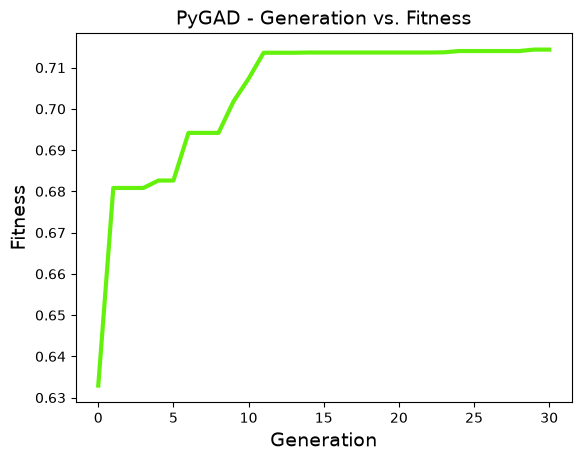

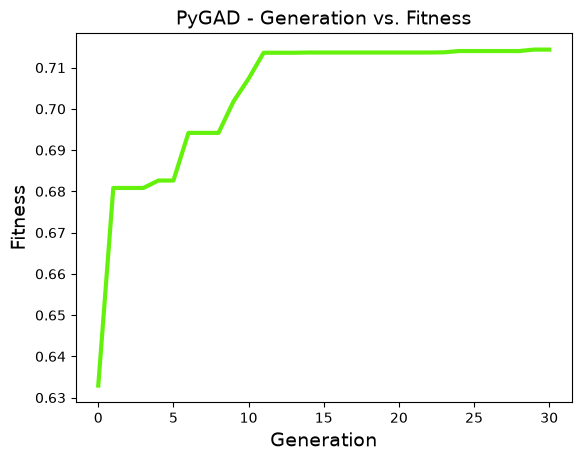

In [22]:
ga_instance.plot_fitness()

## Fase 4: Reentrenamiento del Modelo Optimizado

In [23]:
best_model = build_model_from_chromosome(
    learning_rate, batch_size, optimizer_name, filters, kernel_size, dense_units, dropout
)
best_model.summary()

print(f"Batch size: {batch_size}")

start_time = time.time()
history_best = best_model.fit(
    x_train_norm, y_train_cat,
    validation_data=(x_val_norm, y_val_cat),
    epochs=EPOCHS,  # 30, la misma constante del baseline
    batch_size=batch_size
)
best_train_time = time.time() - start_time

print(f'Tiempo de entrenamiento (modelo optimizado): {best_train_time:.2f}s')

/home/Jesus/miniconda3/envs/ml-course/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 44)     │         1,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 44)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 25)     │         9,925 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 25)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 20)       │         4,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 180)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 103)            │        18,643 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 103)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,360 (138.12 KB)

 Trainable params: 35,360 (138.12 KB)

 Non-trainable params: 0 (0.00 B)

Batch size: 33
Epoch 1/30


I0000 00:00:1790717280.627815    7694 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12079799__.44


1080/1091 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3879 - loss: 1.6617

I0000 00:00:1790717285.130259    7696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12079799__.44


1091/1091 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.3891 - loss: 1.6593 - val_accuracy: 0.5005 - val_loss: 1.3939
Epoch 2/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5298 - loss: 1.3085 - val_accuracy: 0.5609 - val_loss: 1.2115
Epoch 3/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5784 - loss: 1.1783 - val_accuracy: 0.5992 - val_loss: 1.1303
Epoch 4/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6086 - loss: 1.0990 - val_accuracy: 0.6134 - val_loss: 1.0819
Epoch 5/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6347 - loss: 1.0247 - val_accuracy: 0.6337 - val_loss: 1.0386
Epoch 6/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6552 - loss: 0.9734 - val_accuracy: 0.6455 - val_loss: 1.0173
Epoch 7/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6711 - loss: 0.9272 - val_accuracy: 0.6446 - val_loss: 1.0035
Epoch 8/30
1091/1091 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6847 - loss: 0.8904 - val_accurac

## Fase 5: Evaluación Final

In [24]:
resultados_best = best_model.evaluate(x_test_norm, y_test_cat, return_dict=True)
best_test_accuracy = resultados_best['accuracy']
best_params = best_model.count_params()

print(f"Accuracy en Test (optimizado): {best_test_accuracy:.4f}")
print(f"Parámetros entrenables (optimizado): {best_params}")
print(f"Tiempo de entrenamiento (optimizado): {best_train_time:.2f}s")

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6786 - loss: 1.0481
Accuracy en Test (optimizado): 0.6786
Parámetros entrenables (optimizado): 35360
Tiempo de entrenamiento (optimizado): 99.24s


In [25]:
comparacion = pd.DataFrame({
    "Métrica": ["Accuracy en Test", "Parámetros entrenables", "Tiempo de entrenamiento (s)"],
    "Baseline": [test_accuracy, baseline_params, baseline_train_time],
    "Optimizada": [best_test_accuracy, best_params, best_train_time]
})
comparacion

,Métrica,Baseline,Optimizada
0,Accuracy en Test,0.646083,0.678583
1,Parámetros entrenables,315722.000000,35360.000000
2,Tiempo de entrenamiento (s),116.812282,99.238315


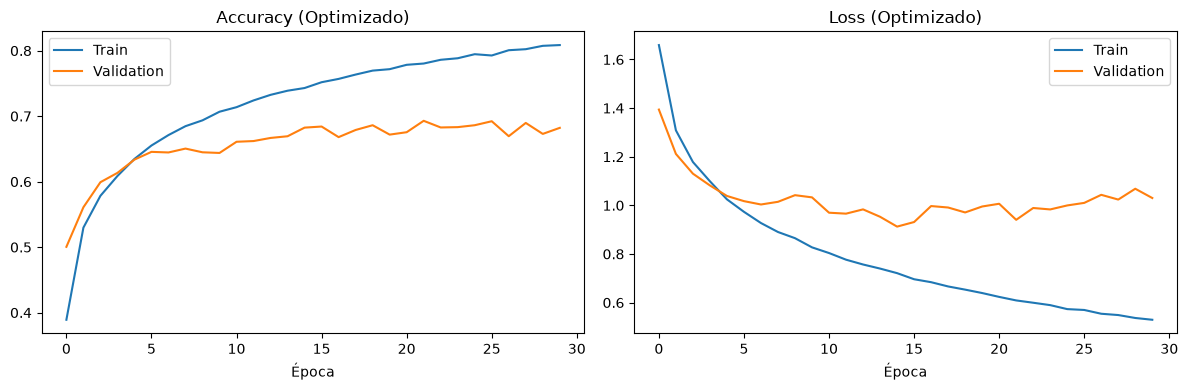

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_best.history['accuracy'], label='Train')
axes[0].plot(history_best.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy (Optimizado)')
axes[0].set_xlabel('Época')
axes[0].legend()

axes[1].plot(history_best.history['loss'], label='Train')
axes[1].plot(history_best.history['val_loss'], label='Validation')
axes[1].set_title('Loss (Optimizado)')
axes[1].set_xlabel('Época')
axes[1].legend()

plt.tight_layout()
plt.show()

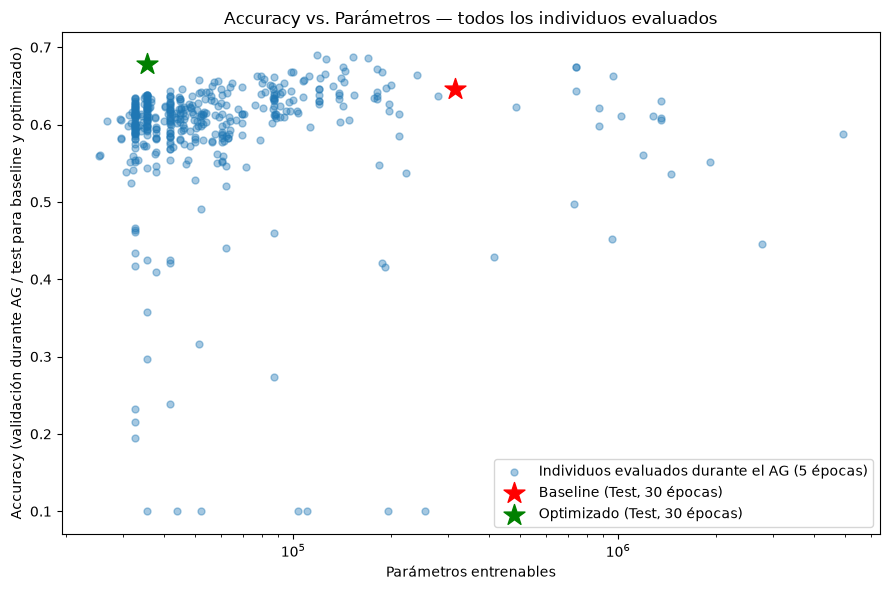

In [28]:
plt.figure(figsize=(9, 6))
plt.scatter(df_eval_log['trainable_params'], df_eval_log['val_accuracy'],
            alpha=0.4, s=25, label='Individuos evaluados durante el AG (5 épocas)')
plt.scatter([baseline_params], [test_accuracy], color='red', marker='*', s=250,
            label='Baseline (Test, 30 épocas)', zorder=5)
plt.scatter([best_params], [best_test_accuracy], color='green', marker='*', s=250,
            label='Optimizado (Test, 30 épocas)', zorder=5)
plt.xlabel('Parámetros entrenables')
plt.ylabel('Accuracy (validación durante AG / test para baseline y optimizado)')
plt.title('Accuracy vs. Parámetros — todos los individuos evaluados')
plt.xscale('log')
plt.legend()
plt.tight_layout()
plt.show()